# Master — MOZAK (sve lezije): EVALUACIJA v2



## Ćelija 0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q nnunetv2 nibabel

import os, shutil, json, subprocess
import numpy as np
import nibabel as nib
from scipy.ndimage import label

MASTER = '/content/drive/MyDrive/Master/mozak'
os.environ['nnUNet_raw']          = f'{MASTER}/podaci_nnunet/nnUNet_raw'
os.environ['nnUNet_preprocessed'] = '/content/nnUNet_preprocessed'
os.environ['nnUNet_results']      = f'{MASTER}/modeli/nnUNet_results'

import torch
print('GPU:', torch.cuda.is_available())

mdir = f"{os.environ['nnUNet_results']}/Dataset001_MsBrain/nnUNetTrainer_100epochs__nnUNetPlans__3d_fullres/fold_0"
print('model folder:', mdir)
print('sadržaj:', os.listdir(mdir) if os.path.exists(mdir) else 'NEMA — trening nije završen?')

CKPT = 'checkpoint_best.pth'


Mounted at /content/drive
GPU: True
model folder: /content/drive/MyDrive/Master/mozak/modeli/nnUNet_results/Dataset001_MsBrain/nnUNetTrainer_100epochs__nnUNetPlans__3d_fullres/fold_0
sadržaj: ['checkpoint_latest.pth', 'training_log_2026_10_21_09_38_53.txt', 'debug.json', 'checkpoint_best.pth', 'progress.png', 'training_log_2026_10_22_08_21_09.txt']


## Ćelija 1 — metrike (Dice + lezijske) i pomoćne funkcije

In [ ]:
import csv

STRUKT = np.ones((3,3,3), int)
def ucitaj(p): return np.asarray(nib.load(p).dataobj)

def dice(pred, gt):
    p = pred > 0; t = gt > 0
    if p.sum() + t.sum() == 0: return np.nan
    return float(2*(p & t).sum() / (p.sum() + t.sum()))

def lezijske(pred, gt):
    gl, ng = label(gt > 0, STRUKT); pl, npr = label(pred > 0, STRUKT)
    pm = pred > 0; gm = gt > 0
    tp = sum(1 for i in range(1, ng+1) if pm[gl == i].any())
    fp = sum(1 for j in range(1, npr+1) if not gm[pl == j].any())
    fn = ng - tp
    return dict(n_gt=ng, n_pred=npr, FP=fp,
                LTPR=tp/ng if ng else np.nan, LFPR=fp/npr if npr else 0.0,
                F1=2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else np.nan)

def red(ime, pred, gt, **extra):
    L = lezijske(pred, gt)
    return dict(pacijent=ime, Dice=dice(pred, gt), vox_pred=int((pred > 0).sum()), **L, **extra)

def ci95(vals, B=2000, seed=0):
    v = np.array([x for x in vals if x == x])
    if len(v) < 2: return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    m = [rng.choice(v, len(v), replace=True).mean() for _ in range(B)]
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def protokol(rows, naziv, ref=None, stampaj=True):
    """Protokol iz rada / MSSEG-2: Dice samo za pacijente SA lezijama;
       za pacijente BEZ lezija broje se lazne detekcije."""
    les = [r for r in rows if r['n_gt'] > 0]; bez = [r for r in rows if r['n_gt'] == 0]
    out = dict(skup=naziv, n_sa=len(les), n_bez=len(bez))
    if les:
        d = [r['Dice'] for r in les]; lo, hi = ci95(d)
        out.update(Dice=float(np.nanmean(d)), CI_lo=lo, CI_hi=hi,
                   LTPR=float(np.nanmean([r['LTPR'] for r in les])),
                   LFPR=float(np.nanmean([r['LFPR'] for r in les])),
                   F1=float(np.nanmean([r['F1'] for r in les])))
    if bez:
        fp = [r['n_pred'] for r in bez]
        out.update(FP_bez=float(np.mean(fp)), bez_cisto=int(sum(1 for x in fp if x == 0)))
    if stampaj:
        print(f"\n=== {naziv} ===")
        if les:
            print(f"  SA lezijama (n={len(les)}): Dice={out['Dice']:.3f} [95% CI {out['CI_lo']:.3f}-{out['CI_hi']:.3f}]  "
                  f"LTPR={out['LTPR']:.3f}  LFPR={out['LFPR']:.3f}  F1={out['F1']:.3f}"
                  + (f"   | baseline: {ref}" if ref is not None else ""))
        if bez:
            print(f"  BEZ lezija (n={len(bez)}): prosecno laznih lezija={out['FP_bez']:.2f}; "
                  f"bez ijedne lazne: {out['bez_cisto']}/{len(bez)}")
    return out

def u_csv(rows, path):
    if not rows: return
    keys = list(rows[0].keys())
    for r in rows:
        for k in r:
            if k not in keys: keys.append(k)
    with open(path, 'w', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=keys); w.writeheader()
        for r in rows: w.writerow(r)
    print('sacuvano:', path)

def predict(in_dir, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    cmd = ['nnUNetv2_predict', '-i', in_dir, '-o', out_dir, '-d', '1', '-c', '3d_fullres',
           '-f', '0', '-tr', 'nnUNetTrainer_100epochs', '-chk', CKPT]
    print('pokrecem predikciju...'); subprocess.run(cmd, check=True)

PO_PAC = []   # svi pacijenti, svi skupovi
def oceni(parovi, naziv, ref=None, ulaz=None):
    rows = [red(ime, ucitaj(pp), ucitaj(gp) > 0, skup=naziv, pred_put=pp, gt_put=gp,
                flair=(f'{ulaz}/{ime}_0000.nii.gz' if ulaz else None)) for ime, pp, gp in parovi]
    PO_PAC.extend(rows)
    return protokol(rows, naziv, ref)

REZ = {}
print('funkcije spremne.')

funkcije spremne.


## Ćelija 2 — MS3SEG interni test + MSLesSeg test

In [ ]:
import random, requests, zipfile
STARO = '/content/drive/MyDrive/ms projekat'

s_dir = f'{STARO}/ms3seg/snimci'; m_dir = f'{STARO}/ms3seg/maske'
ms3 = []
for pid in sorted(os.listdir(s_dir)):
    s = f'{s_dir}/{pid}/{pid}_FLAIR.nii.gz'; m = f'{m_dir}/{pid}/{pid}_abWMH_Mask.nii.gz'
    if os.path.exists(s) and os.path.exists(m): ms3.append((f'ms3_{pid}', s, m))
pids = sorted(c for c, _, _ in ms3); random.seed(42); random.shuffle(pids)
test_ids = set(pids[85:])
ms3_ts = [x for x in ms3 if x[0] in test_ids]
print('MS3SEG interni test:', len(ms3_ts))

if not os.path.exists('/content/mslesseg/MSLesSeg Dataset'):
    print('skidam MSLesSeg...')
    with requests.get('https://ndownloader.figshare.com/files/52771814', stream=True) as r:
        with open('/content/mslesseg.zip', 'wb') as fh:
            for ch in r.iter_content(1 << 20): fh.write(ch)
    zipfile.ZipFile('/content/mslesseg.zip').extractall('/content/mslesseg')
tdir = '/content/mslesseg/MSLesSeg Dataset/test'
mls_ts = []
for pac in sorted(os.listdir(tdir)):
    f_ = f'{tdir}/{pac}/{pac}_FLAIR.nii.gz'; m_ = f'{tdir}/{pac}/{pac}_MASK.nii.gz'
    if os.path.exists(f_) and os.path.exists(m_): mls_ts.append((f'mls_{pac}', f_, m_))
print('MSLesSeg test:', len(mls_ts))

in_ts = '/content/ts_in'; out_ts = '/content/ts_out'
shutil.rmtree(in_ts, ignore_errors=True); os.makedirs(in_ts)
for cid, s, m in ms3_ts + mls_ts: shutil.copy(s, f'{in_ts}/{cid}_0000.nii.gz')
predict(in_ts, out_ts)
REZ['MS3SEG (interni)'] = oceni([(c, f'{out_ts}/{c}.nii.gz', m) for c, _, m in ms3_ts], 'MS3SEG (interni test)', ref=0.685, ulaz=in_ts)
REZ['MSLesSeg (korišćen u obuci)'] = oceni([(c, f'{out_ts}/{c}.nii.gz', m) for c, _, m in mls_ts], 'MSLesSeg (test)', ref=0.556, ulaz=in_ts)

MS3SEG interni test: 15
skidam MSLesSeg...
MSLesSeg test: 22
pokrecem predikciju...

=== MS3SEG (interni test) ===
  SA lezijama (n=15): Dice=0.814 [95% CI 0.789-0.841]  LTPR=0.850  LFPR=0.224  F1=0.802   | baseline: 0.685

=== MSLesSeg (test) ===
  SA lezijama (n=22): Dice=0.702 [95% CI 0.659-0.743]  LTPR=0.734  LFPR=0.244  F1=0.723   | baseline: 0.556


## Ćelija 3 — open_ms_data

In [ ]:
import os
os.chdir('/content')
if not os.path.exists('/content/open_ms_data'):
    !git clone -q https://github.com/muschellij2/open_ms_data.git

base = '/content/open_ms_data/cross_sectional/coregistered_resampled'
in_o = '/content/eval_oms/in'; out_o = '/content/eval_oms/out'
os.makedirs(in_o, exist_ok=True)
gt_map = {}
for pac in sorted(os.listdir(base)):
    fl = f'{base}/{pac}/FLAIR.nii.gz'; gt = f'{base}/{pac}/consensus_gt.nii.gz'
    if os.path.exists(fl) and os.path.exists(gt):
        shutil.copy(fl, f'{in_o}/{pac}_0000.nii.gz')
        gt_map[pac] = gt
predict(in_o, out_o)
par = [(pac, f'{out_o}/{pac}.nii.gz', gt_map[pac]) for pac in gt_map if os.path.exists(f'{out_o}/{pac}.nii.gz')]
REZ['open_ms_data (nezavisan)'] = oceni(par, 'open_ms_data (nezavisan)', ref=0.511, ulaz=in_o)

pokrecem predikciju...

=== open_ms_data (nezavisan) ===
  SA lezijama (n=30): Dice=0.551 [95% CI 0.469-0.627]  LTPR=0.304  LFPR=0.165  F1=0.428   | baseline: 0.511


## Ćelija 4 — MSSEG-2016 (nezavisan, konsenzus 7 eksperata)

In [ ]:
import glob, os, shutil

ms16 = []
for pdir in sorted(glob.glob('/content/msseg2016/Training/Center_*/Patient_*')):
    fl = f'{pdir}/Preprocessed_Data/FLAIR_preprocessed.nii.gz'
    mk = f'{pdir}/Masks/Consensus.nii.gz'
    if os.path.exists(fl) and os.path.exists(mk):
        c, p = pdir.split('/')[-2:]
        ms16.append((f"ms16_{c.split('_')[1]}_{p.split('_')[1]}", fl, mk))
print('MSSEG-2016 pacijenata nađeno:', len(ms16))

in_16 = '/content/ts16_in'; out_16 = '/content/ts16_out'
shutil.rmtree(in_16, ignore_errors=True); os.makedirs(in_16)
for cid, s, m in ms16:
    shutil.copy(s, f'{in_16}/{cid}_0000.nii.gz')
print('pokrecem predikciju...')
predict(in_16, out_16)
REZ['MSSEG-2016 (nezavisan)'] = oceni([(c, f'{out_16}/{c}.nii.gz', m) for c, _, m in ms16],
                                      'MSSEG-2016 (konsenzus 7 eksperata)', ulaz=in_16)

MSSEG-2016 pacijenata nađeno: 15
pokrecem predikciju...
pokrecem predikciju...

=== MSSEG-2016 (konsenzus 7 eksperata) ===
  SA lezijama (n=15): Dice=0.651 [95% CI 0.588-0.712]  LTPR=0.600  LFPR=0.193  F1=0.645


## Ćelija 5 — finalna tabela: nnU-Net vs stari ručni U-Net

In [ ]:
from datetime import datetime
STARI = {'MS3SEG (interni)': 0.685, 'MSLesSeg (korišćen u obuci)': 0.556, 'open_ms_data (nezavisan)': 0.511}
print(f"{'Skup':<30}{'n':>4}{'nnU-Net Dice':>13}{'95% CI':>16}{'stari':>8}{'LTPR':>7}{'LFPR':>7}{'F1':>7}")
print('-' * 92)
for k, r in REZ.items():
    if 'Dice' not in r:
        print(f"[preskačem] '{k}': {r}")
        continue
    s = f"{STARI[k]:.3f}" if k in STARI else '  —  '
    ci = f"{r['CI_lo']:.3f}-{r['CI_hi']:.3f}" if 'CI_lo' in r else '   —   '
    print(f"{k:<30}{r['n_sa']:>4}{r['Dice']:>13.3f}{ci:>16}{s:>8}{r['LTPR']:>7.3f}{r['LFPR']:>7.3f}{r['F1']:>7.3f}")
ts = datetime.now().strftime('%Y%m%d_%H%M')
rd = f'{MASTER}/rezultati'; os.makedirs(rd, exist_ok=True)
u_csv(PO_PAC, f'{rd}/mozak_sve_lezije_po_pacijentu_{ts}.csv')
u_csv([dict(skup_kljuc=k, **r) for k, r in REZ.items()], f'{rd}/mozak_sve_lezije_SAZETAK_{ts}.csv')

Skup                             n nnU-Net Dice          95% CI   stari   LTPR   LFPR     F1
--------------------------------------------------------------------------------------------
MS3SEG (interni)                15        0.814     0.789-0.841   0.685  0.850  0.224  0.802
MSLesSeg (korišćen u obuci)     22        0.702     0.659-0.743   0.556  0.734  0.244  0.723
open_ms_data (nezavisan)        30        0.551     0.469-0.627   0.511  0.304  0.165  0.428
MSSEG-2016 (nezavisan)          15        0.651     0.588-0.712     —    0.600  0.193  0.645
sacuvano: /content/drive/MyDrive/Master/mozak/rezultati/mozak_sve_lezije_po_pacijentu_20261113_0819.csv
sacuvano: /content/drive/MyDrive/Master/mozak/rezultati/mozak_sve_lezije_SAZETAK_20261113_0819.csv


## Ćelija 6 — SLIKE: svaki pacijent + pregled najbolji / srednji / najgori
Za svakog pacijenta: presek sa najviše lezija. **Žuto** = model i lekar se slažu, **zeleno** = lezija koju je model promašio, **crveno** = lažna detekcija.
Snima se u `Master/mozak/rezultati/slike_mozak/`, a pregled se prikaže i ovde.

slike po pacijentu sacuvane u /content/drive/MyDrive/Master/mozak/rezultati/slike_mozak


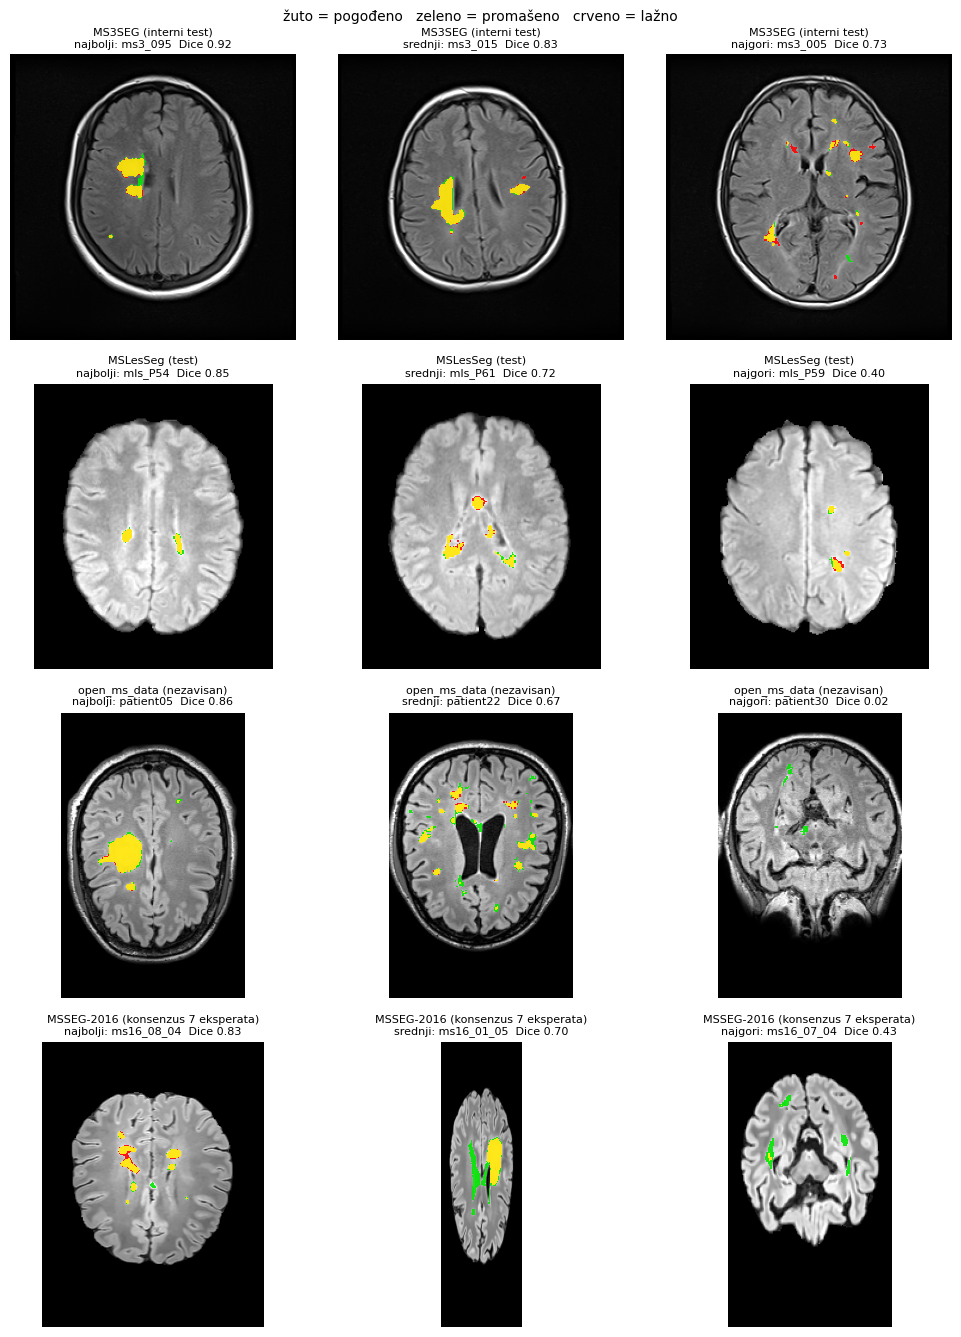

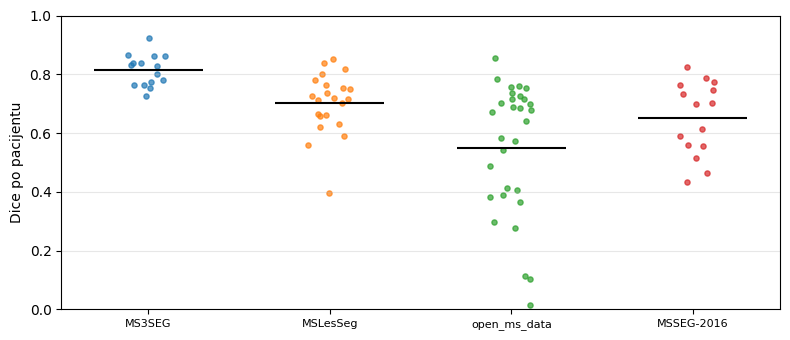

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
SL = f'{MASTER}/rezultati/slike_mozak'; os.makedirs(SL, exist_ok=True)

def presek(r):
    fl = ucitaj(r['flair']).astype(float); gt = ucitaj(r['gt_put']) > 0; pr = ucitaj(r['pred_put']) > 0
    z = int(np.argmax(gt.sum(axis=(0, 1)))) if gt.any() else int(np.argmax(pr.sum(axis=(0, 1))))
    f = fl[:, :, z]; lo, hi = np.percentile(f, [1, 99.5]); f = np.clip((f - lo) / (hi - lo + 1e-6), 0, 1)
    ov = np.zeros(f.shape, int)
    ov[gt[:, :, z] & pr[:, :, z]] = 1; ov[gt[:, :, z] & ~pr[:, :, z]] = 2; ov[~gt[:, :, z] & pr[:, :, z]] = 3
    return np.rot90(f), np.rot90(ov), z

CM = ListedColormap([(0, 0, 0, 0), (1, 0.9, 0, 0.9), (0, 0.9, 0, 0.9), (1, 0, 0, 0.9)])
def crtaj(ax, r, naslov=True):
    f, ov, z = presek(r)
    ax.imshow(f, cmap='gray'); ax.imshow(np.ma.masked_where(ov == 0, ov), cmap=CM, vmin=0, vmax=3, interpolation='nearest')
    ax.axis('off')
    if naslov: ax.set_title(f"{r['pacijent']}\nDice {r['Dice']:.2f} | lezija {r['n_gt']} | lažnih {r['FP']}", fontsize=8)

# 1) slika za svakog pacijenta
for r in PO_PAC:
    if not r.get('flair') or not os.path.exists(r['flair']): continue
    fig, ax = plt.subplots(figsize=(4, 4)); crtaj(ax, r)
    d = f"{SL}/{r['skup'].split(' (')[0].replace(' ', '_')}"; os.makedirs(d, exist_ok=True)
    fig.savefig(f"{d}/{r['Dice']:.3f}_{r['pacijent']}.png", dpi=120, bbox_inches='tight'); plt.close(fig)
print('slike po pacijentu sacuvane u', SL)

# 2) pregled: za svaki skup najbolji, srednji i najgori pacijent
skupovi = list(dict.fromkeys(r['skup'] for r in PO_PAC))
fig, axs = plt.subplots(len(skupovi), 3, figsize=(10, 3.4 * len(skupovi)), squeeze=False)
for i, s in enumerate(skupovi):
    rs = sorted([r for r in PO_PAC if r['skup'] == s and r.get('flair') and r['Dice'] == r['Dice']], key=lambda r: r['Dice'])
    if not rs: continue
    for j, (ime, r) in enumerate([('najbolji', rs[-1]), ('srednji', rs[len(rs) // 2]), ('najgori', rs[0])]):
        crtaj(axs[i, j], r); axs[i, j].set_title(f"{s}\n{ime}: {r['pacijent']}  Dice {r['Dice']:.2f}", fontsize=8)
fig.suptitle('žuto = pogođeno   zeleno = promašeno   crveno = lažno', fontsize=10)
plt.tight_layout(); fig.savefig(f'{SL}/PREGLED_najbolji_srednji_najgori.png', dpi=130); plt.show()

# 3) raspored Dice po pacijentu za svaki skup (da se vidi da li prosek diže par pacijenata)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, s in enumerate(skupovi):
    d = [r['Dice'] for r in PO_PAC if r['skup'] == s and r['Dice'] == r['Dice']]
    ax.scatter(np.full(len(d), i) + np.random.uniform(-0.12, 0.12, len(d)), d, s=14, alpha=0.7)
    ax.hlines(np.mean(d), i - 0.3, i + 0.3, color='k')
ax.set_xticks(range(len(skupovi))); ax.set_xticklabels([s.split(' (')[0] for s in skupovi], fontsize=8)
ax.set_ylabel('Dice po pacijentu'); ax.set_ylim(0, 1); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); fig.savefig(f'{SL}/RASPORED_dice.png', dpi=130); plt.show()